In [9]:
import pandas as pd
import csv
import matplotlib.pyplot as plt

import re 
import shutil
import numpy as np
%matplotlib inline
import subprocess
import os
import scipy.io as sio
from mpl_toolkits.axes_grid1 import AxesGrid
from collections import OrderedDict
import matplotlib.pyplot as plt
import mayavi.mlab as mlab
import copy
import time
import scipy.io as sio
import matplotlib.pyplot as plt
import numpy as np
import shdom
from shdom import float_round
fontsize = 20
from shdom.CloudCT_Utils import *
import yaml


lw = 1.5
from mpl_toolkits.axes_grid1 import AxesGrid, make_axes_locatable

In [156]:
def load_run_params(params_path):
    """
    TODO
    Args:
        params_path ():

    Returns:

    """
    # Load run parameters
    params_file_path = params_path
    with open(params_file_path, 'r') as f:
        run_params = yaml.full_load(f)
    return run_params

def calc_extinction(LWC, REFF):
    ro = 1e6 # gram/m^3
    extinction =  (3/(2*ro))*(LWC/(REFF*1e-6)) # in i/m units
    extinction = np.nan_to_num(extinction)
    
    if np.isinf(extinction).any():
        extinction[np.isinf(extinction)]=0
        
    if (extinction>10000).any():
        extinction[extinction>10000]=0
            
    return extinction*1e3 # in i/km units

In [215]:
CloudFieldFile = "/wdata_visl/generated_clouds/generated_clouds_mat_mul_by_10_xyz/cloud41628.txt" 
# CloudFieldFile = "/wdata_visl/generated_clouds/clouds/cloud1954.txt" # lwc: 0.8 reff: 6.2

run_params = load_run_params(params_path="../CloudCT_scripts/run_params.yaml")
mie_options = run_params['mie_options']

mie_table_path = "/wdata_visl/generated_clouds/mie_tables/polydisperse/averaged_Water_647nm.scat"
# mie_table_path = "/wdata_visl/generated_clouds/mie_tables/polydisperse/Water_650nm.scat"
wavelength = 0.647
# wavelength = 0.65

mie = shdom.MiePolydisperse()
mie.read_table(mie_table_path)

droplets = shdom.MicrophysicalScatterer()
droplets.load_from_csv(CloudFieldFile)

lwc = droplets.lwc.data
veff = droplets.veff.data
reff = droplets.reff.data

start_veff = mie_options['start_veff']
start_reff = mie_options['start_reff']
# start_reff = 4.0
end_veff = mie_options['end_veff']
# end_veff = 0.2
end_reff = mie_options['end_reff']
# veff[veff<=start_veff] = start_veff
# veff[veff>=end_veff] = end_veff 

reff[reff<=start_reff] = start_reff
reff[reff>=end_reff] = end_reff 
# optical depth:
droplets.add_mie(mie) 

medium = shdom.Medium(droplets.grid)
# add a scatterer to the medium:
medium.add_scatterer(droplets, name='clouds')

cloud = medium.get_scatterer(name='clouds')
reff = cloud.reff.data
veff = cloud.veff.data
lwc = cloud.lwc.data
extinction_at_wavelength = cloud.get_extinction(wavelength=wavelength)

Reading mie table from file: /wdata_visl/generated_clouds/mie_tables/polydisperse/averaged_Water_647nm.scat


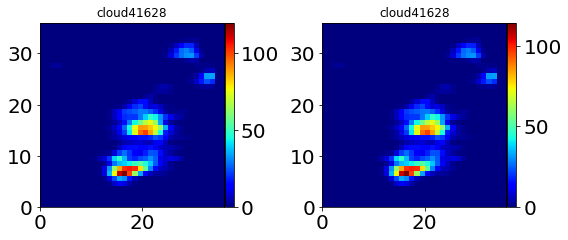

In [216]:
z = extinction_at_wavelength.grid.z
x = extinction_at_wavelength.grid.x
y = extinction_at_wavelength.grid.y
nx,ny,nz = extinction_at_wavelength.shape
X,Y,Z = np.meshgrid(x,y,z,indexing='ij')
DZ = np.diff(Z)
DZ = np.pad(DZ, ((0, 0), (0, 0), (0, 1)), 'constant', constant_values=DZ[0,0,nz-2])
optical_depth = np.sum(DZ*extinction_at_wavelength.data, axis=2)

fig,ax = plt.subplots(1,2,figsize=(8, 6))
im = ax[0].imshow(optical_depth, vmin=0, vmax=optical_depth.max(),\
                           extent=[0, optical_depth.shape[1], 0, optical_depth.shape[0]], cmap='jet')
ax[0].grid(False)
ax[0].set_title(CloudFieldFile.split('/')[-1].split('.')[0])

divider = make_axes_locatable(ax[0])
cax = divider.append_axes("right", size="5%", pad=0.01)
cbar = plt.colorbar(im, cax=cax) 

cbar.ax.tick_params(labelsize=20) 
ax[0].xaxis.set_tick_params(labelsize=20)
ax[0].yaxis.set_tick_params(labelsize=20)   

# calculate extinction with estimation:
extinction_estimated = calc_extinction(lwc, reff)
optical_depth_estimated = np.sum(DZ*extinction_estimated, axis=2)

im = ax[1].imshow(optical_depth_estimated, vmin=0, vmax=optical_depth_estimated.max(),\
                           extent=[0, optical_depth_estimated.shape[1], 0, optical_depth_estimated.shape[0]], cmap='jet')
ax[1].grid(False)
ax[1].set_title(CloudFieldFile.split('/')[-1].split('.')[0])

divider = make_axes_locatable(ax[1])
cax = divider.append_axes("right", size="5%", pad=0.01)
cbar = plt.colorbar(im, cax=cax) 

cbar.ax.tick_params(labelsize=20) 
ax[1].xaxis.set_tick_params(labelsize=20)
ax[1].yaxis.set_tick_params(labelsize=20)    

plt.tight_layout()


# Calculate the optical depth for validation + save txt file for the spesific cloud/s

/wdata_visl/generated_clouds/generated_clouds_mat_mul_by_10_xyz/cloud41628.mat


/home/vhold/miniconda3/envs/pyshdom/lib/python3.7/site-packages/ipykernel_launcher.py:18: RuntimeWarning: invalid value encountered in true_divide


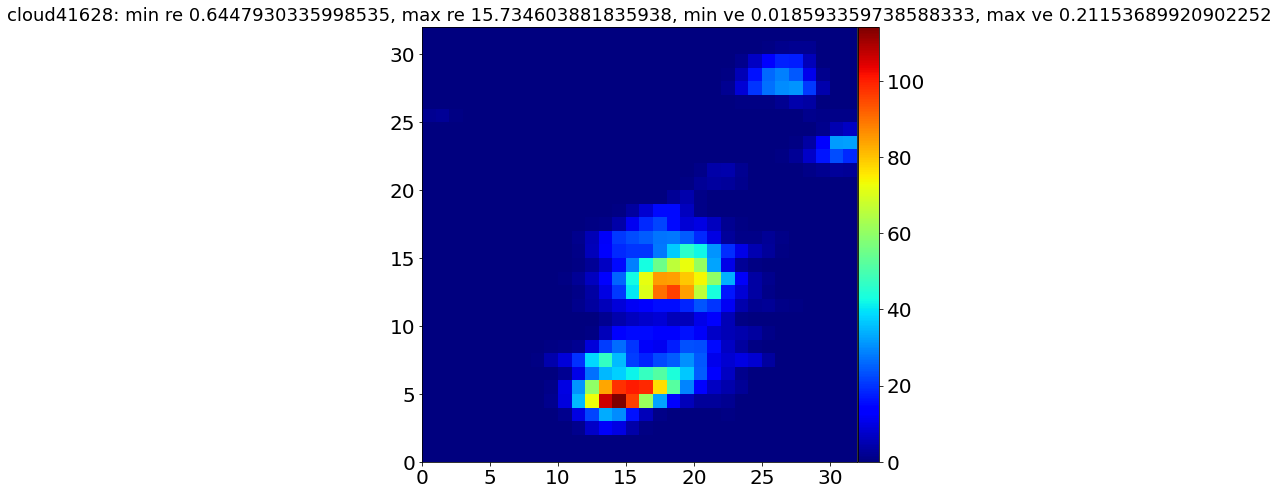

In [214]:
# ref_path = "/wdata_visl/generated_clouds/original_clouds_w_txt"
# ref_path = "/wdata_visl/generated_clouds/clouds/"
ref_path = "/wdata_visl/generated_clouds/generated_clouds_mat_mul_by_10_xyz/"

# ref_path = "/wdata/roironen/Data/BOMEX_256x256x100_5000CCN_50m_micro_256/clouds/"
# ref_path = "/wdata_visl/vhold/CloudCT_153/pyshdom_153/synthetic_cloud_fields/yael_to_show/"
# ref_path = "/wdata_visl/NEW_BOMEX/processed_BOMEX_256x256x100_5000CCN_50m/"

USE_MAT = True
cloud_list = [29718, 13451, 40297, 41211, 41628, 19818]
cloud_list = [41628]

# good_cloud_list = [20177]


# I always do the padding. 
# I Pad with zeros on the sides and bottom top.
# So:
PAD_ON_SIDE   = 2 # how much to pad each side?
PAD_ON_BOTTOM = 2 # how much to pad bottom?
PAD_ON_TOP    = 2 # how much to pad top?


fh = 0
for filename in os.listdir(ref_path):
    if USE_MAT:
        formater = ".mat"
    else:
        formater = ".txt"
        
    
    if filename.endswith(formater):
        
        if not int(filename.split('d')[-1].split('.')[0]) in cloud_list:
            continue
            
#         if not int(filename.split('d')[-1].split('.')[0]) in good_cloud_list:
#             continue
        
        filepath = os.path.join(ref_path, filename)
        print(filepath)
        
        droplets = shdom.MicrophysicalScatterer()
        if USE_MAT:
            DATA_DICT = sio.loadmat(filepath)
            lwc = DATA_DICT['data'][2,...] # DATA_DICT['lwc']
            veff = DATA_DICT['data'][1,...] # DATA_DICT['veff']
            reff = DATA_DICT['data'][0,...] # DATA_DICT['reff']
            
            lwc[reff<0.1] = 0
            veff[reff<0.1] = 0
            reff[reff<0.1] = 0
            
            reff[lwc<0.001] = 0
            veff[lwc<0.001] = 0
            lwc[lwc<0.001] = 0
            
            # veff[lwc>0.001] = 0.1
            
            
            field_DATA_DICT = OrderedDict()
            for data_name in ('lwc' , 'reff', 'veff'):
                field = eval(data_name)
                new_field = np.pad(field, ((PAD_ON_SIDE, PAD_ON_SIDE), \
                                   (PAD_ON_SIDE, PAD_ON_SIDE), \
                                   (PAD_ON_BOTTOM, PAD_ON_TOP)),\
                       'constant', constant_values=0)
                
                field_DATA_DICT[data_name] = new_field
                
            nx,ny,nz = new_field.shape
            dx = 0.05
            dy = 0.05
            dz = 0.04

            xgrid = np.linspace(0,(nx - 1), nx)
            ygrid = np.linspace(0,(ny - 1), ny)
            zgrid = np.linspace(0,(nz - 1), nz)
            x,y,z = np.meshgrid(xgrid, ygrid, zgrid, indexing='ij')

            file_name = os.path.join(ref_path, filename.split('.')[0]+'.txt')
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------
            comment_line = '# Generated by tamar'
            # save in the old version:
            with open(file_name, 'w') as f:
                
                f.write(comment_line + "\n")
                # nx,ny,nz # nx,ny,nz
                f.write('{} {} {} '.format(int(nx),\
                                            int(ny),\
                                            int(nz),\
                                            ) + "\n")

                # dx,dy ,z
                np.savetxt(f, X=np.concatenate((np.array([dx, dy]), dz*zgrid)).reshape(1,-1), fmt='%2.3f')
                # z_levels[0]     z_levels[1] ...  z_levels[nz-1] 



                data = np.vstack((x.ravel(), y.ravel(), z.ravel(),\
                                  field_DATA_DICT['lwc'].ravel(),\
                                  field_DATA_DICT['reff'].ravel(),\
                                  field_DATA_DICT['veff'].ravel())).T
                # Delete unnecessary rows e.g. zeros in lwc
                mask = field_DATA_DICT['lwc'].ravel() > 0
                data = data[mask,...]
                np.savetxt(f, X=data, fmt='%d %d %d %.5f %.3f %.5f')
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------
            #--------------------------------------------------------------------

            
#             grid_x = DATA_DICT['x']
#             grid_z = DATA_DICT['z']
#             grid_y = DATA_DICT['y']

#             x_max = int((DATA_DICT['x'][0][-1]/0.05) + 1)
#             y_max = int((DATA_DICT['y'][0][-1]/0.05) + 1)
#             z_max = int((DATA_DICT['z'][0][-1]/0.04) + 1)

#             bounding_box = shdom.BoundingBox(0,
#                                          0,
#                                          0,
#                                          x_max,
#                                          y_max,
#                                          z_max)

#             grid = shdom.Grid(bounding_box=bounding_box,\
#                               nx=grid_x.size,
#                           ny=grid_y.size,
#                           nz=grid_z.size)
            
        else: # use text:
            droplets.load_from_csv(filepath)
            lwc = droplets.lwc.data
            reff = droplets.reff.data
        
        
        min_reff = reff[reff>0].min()
        max_reff = reff[reff>0].max()
        
        min_veff = veff[veff>0].min()
        max_veff = veff[veff>0].max()
        
        
        extinction_estimated = calc_extinction(lwc, reff)
        optical_depth_estimated = np.sum(0.04*extinction_estimated, axis=2)
        
#         lwc = shdom.GridData(grid,lwc)
#         veff = shdom.GridData(grid,veff)
#         reff = shdom.GridData(grid,reff)
        
        
        if 0:
            droplets = shdom.MicrophysicalScatterer(lwc=lwc,reff=reff,veff=veff)

            start_veff = mie_options['start_veff']
            start_reff = mie_options['start_reff']
            end_veff = mie_options['end_veff']
            end_reff = mie_options['end_reff']
    #         veff[veff<=start_veff] = start_veff
    #         veff[veff>=end_veff] = end_veff 

    #         reff[reff<=start_reff] = start_reff
    #         reff[reff>=end_reff] = end_reff 
            # optical depth:
            droplets.add_mie(mie) 

            medium = shdom.Medium(droplets.grid)
            # add a scatterer to the medium:
            medium.add_scatterer(droplets, name='clouds')

            cloud = medium.get_scatterer(name='clouds')
            reff = cloud.reff.data
            veff = cloud.veff.data
            lwc = cloud.lwc.data
            extinction_at_wavelength = cloud.get_extinction(wavelength=0.647)

            z = extinction_at_wavelength.grid.z
            x = extinction_at_wavelength.grid.x
            y = extinction_at_wavelength.grid.y
            nx,ny,nz = extinction_at_wavelength.shape
            X,Y,Z = np.meshgrid(x,y,z,indexing='ij')
            DZ = np.diff(Z)
            DZ = np.pad(DZ, ((0, 0), (0, 0), (0, 1)), 'constant', constant_values=DZ[0,0,nz-2])
            optical_depth = np.sum(DZ*extinction_at_wavelength.data, axis=2)

        f, ax = plt.subplots(1, 1, figsize=(12, 8))
        im = ax.imshow(optical_depth_estimated, vmin=0, vmax=optical_depth_estimated.max(),\
                                   extent=[0, optical_depth_estimated.shape[1], 0, optical_depth_estimated.shape[0]], cmap='jet')
        ax.grid(False)
        ax.set_title(filename.split('/')[-1].split('.')[0]+": min re {}, max re {}, min ve {}, max ve {}".\
                     format(min_reff,max_reff,min_veff,max_veff), fontsize=18)

        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.01)
        cbar = plt.colorbar(im, cax=cax) 

        cbar.ax.tick_params(labelsize=20) 
        ax.xaxis.set_tick_params(labelsize=20)
        ax.yaxis.set_tick_params(labelsize=20) 
        fh += 1
        
        if(fh ==100):
            break

In [191]:
nx,ny,nz = new_field.shape
print(nx,ny,nz)
dx = 0.05
dy = 0.05
dz = 0.04

xgrid = np.linspace(0,dx*(nx - 1), nx)
ygrid = np.linspace(0,dy*(ny - 1), ny)
zgrid = np.linspace(0,dz*(nz - 1), nz)

print(zgrid)

36 36 36
[0.   0.04 0.08 0.12 0.16 0.2  0.24 0.28 0.32 0.36 0.4  0.44 0.48 0.52
 0.56 0.6  0.64 0.68 0.72 0.76 0.8  0.84 0.88 0.92 0.96 1.   1.04 1.08
 1.12 1.16 1.2  1.24 1.28 1.32 1.36 1.4 ]


In [207]:
np.max(veff[lwc>0.1])

0.17633925

In [166]:
int(filename.split('d')[-1].split('.')[0])

8982

In [144]:
extinction_estimated[np.isinf(extinction_estimated)] = 0

In [145]:
np.isinf(extinction_estimated)

array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, Fal